# Лабораторная работа 1
## Попович Виталий Сергеевич M3407 373324
## Сбор данных

In [1]:
from __future__ import annotations

import itertools
import math
import re
import time
import unicodedata
from collections import Counter, defaultdict
from datetime import datetime, timezone
from pathlib import Path
import xml.etree.ElementTree as ET

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import requests
from IPython.display import display
API_URL = "https://export.arxiv.org/api/query"
SEARCH_QUERY = '(all:"speculative decoding" OR all:"speculative sampling" OR all:"draft-then-verify" OR all:"draft model" OR all:"draft models")'
MIN_DATE = "202001010000"
MAX_DATE = datetime.now(timezone.utc).strftime("%Y%m%d%H%M")
N_PUBLICATIONS, BATCH_SIZE = 400, 100
ATOM = {"a": "http://www.w3.org/2005/Atom"}

def parse_xml(content):
    root = ET.fromstring(content)
    records = []
    for entry in root.findall("a:entry", ATOM):
        authors = [x.findtext("a:name", namespaces=ATOM) for x in entry.findall("a:author", ATOM)]
        categories = [x.attrib.get("term", "") for x in entry.findall("a:category", ATOM)]
        url = entry.findtext("a:id", namespaces=ATOM)
        records.append({
            "arxiv_id": url.rsplit("/", 1)[-1],
            "title": entry.findtext("a:title", namespaces=ATOM),
            "authors": "; ".join(authors),
            "abstract": entry.findtext("a:summary", namespaces=ATOM),
            "published": entry.findtext("a:published", namespaces=ATOM),
            "updated": entry.findtext("a:updated", namespaces=ATOM),
            "categories": "; ".join(categories),
            "url": url,
        })
    return records

def download_arxiv(n=N_PUBLICATIONS, batch_size=BATCH_SIZE):
    session = requests.Session()
    rows = []
    for start in range(0, n, batch_size):
        params = {
            "search_query": f"{SEARCH_QUERY} AND submittedDate:[{MIN_DATE} TO {MAX_DATE}]",
            "start": start,
            "max_results": min(batch_size, n - start),
            "sortBy": "submittedDate",
            "sortOrder": "descending",
        }
        for attempt in range(4):
            try:
                response = session.get(API_URL, params=params, timeout=60)
                response.raise_for_status()
                page = parse_xml(response.content)
                if not page:
                    time.sleep(3)
                    continue
                rows.extend(page)
                print(f"Получено {len(rows):>3}/{n} записей")
                break
            except Exception as exc:
                print(f"Ошибка загрузки блока {start}-{start + batch_size}: {exc}")
                time.sleep(3)
        time.sleep(3)
    return pd.DataFrame(rows).drop_duplicates("arxiv_id").head(n)

if Path("arxiv_speculative_decoding.csv").exists():
    df = pd.read_csv("arxiv_speculative_decoding.csv", encoding="utf-8-sig")
else:
    df = download_arxiv()
    df.to_csv("arxiv_speculative_decoding.csv", index=False, encoding="utf-8-sig")

df["published"] = pd.to_datetime(df["published"], utc=True)
df["updated"] = pd.to_datetime(df["updated"], utc=True)
df["year"] = df["published"].dt.year

display(df[["arxiv_id", "published", "title", "authors", "abstract"]].head(10))

,arxiv_id,published,title,authors,abstract
0,2610.23818v1,2026-10-16 17:41:19+00:00,Acceptance Is Not Speed: Length Inflation in T...,Chiatzen Wang; Bill Xu; Haochen Gu; Hongyang Z...,Speculative decoding typically characterizes s...
1,2610.23787v1,2026-10-16 17:18:54+00:00,DLite: History-free Speculative Decoding for A...,Jiaming Xu; Hanzhen Wang; Tianlang Zhao; Jiewe...,Speculative decoding has become a mainstream t...
2,2610.23613v1,2026-10-16 15:24:05+00:00,Trajectory-Triggered Sparse Collaborative Deco...,Amit Ranjan Trivedi; Sruthikesh Surineni; Kyon...,Dense assistance methods such as speculative d...
3,2610.22877v1,2026-10-16 03:30:21+00:00,BS-Spec: BFP-Based Bit-Sharing for Self-Specul...,Jiwoo Kim; Gunho Park; Sunwoo Yoo; Baeseong Pa...,As large language models (LLMs) are increasing...
4,2610.22543v1,2026-10-15 18:40:42+00:00,On the SPOT: Enhancing Speculative Decoding fo...,Eliezer Shlomi; Eliron Rahimi; Avi Mendelson; ...,Diffusion language models (DLMs) promise paral...
5,2610.21594v1,2026-10-15 09:38:11+00:00,LoopAhead: Speculating Ahead for Faster Decodi...,Zixuan Liu; Nan Xue; Rui Bao; Yuhang Xu; Xiaof...,Looped Transformers improve parameter efficien...
6,2610.21436v1,2026-10-15 07:45:49+00:00,HyCo: Hybrid Drafting for Cost-Efficient Mobil...,Hanbin Bae; Heejin Choi; Joohyung Lee; Byoung ...,Device-cloud speculative decoding reduces serv...
7,2610.20865v1,2026-10-14 19:54:59+00:00,Long-Context Drafting Does Not Require Long-Co...,Aref Jafari; Vansh Bhatia; Matt Qin; Subhajit ...,Speculative decoding pairs a cheap drafter wit...
8,2610.20556v1,2026-10-14 17:45:27+00:00,Speculative Sampling in Interactive Video Gene...,Yubo Huang; Yuxuan Zhang; Jiaming Liu; Sirui Z...,Interactive video generation commonly relies o...
9,2610.20687v1,2026-10-14 17:13:17+00:00,On-Policy Residual Learning for Diffusion Lang...,Yifan Yu; Yuqing Jian; Jisen Li; Yuezhou Hu; T...,Residual context is key to unlocking the speed...


## Разведочный анализ

,Значение
Публикаций,400
Период,2026-02-18 - 2026-10-16
Уникальных авторов,2703
Медиана слов в названии,9.0
Медиана слов в аннотации,183.0
Дубликатов arXiv ID,0
Дубликатов названий,0
Пустых названий,0
Пустых аннотаций,0
Пустых авторов,0


,Публикаций
Автор,
Yuhao Shen,7
Hao Zhang,5
Tianyu Liu,5
Baolin Zhang,4
Ran Zilberstein,4
Yu-Yang Qian,4
Jungseob Lee,4
Xinyi Hu,4
Linfeng Zhang,4


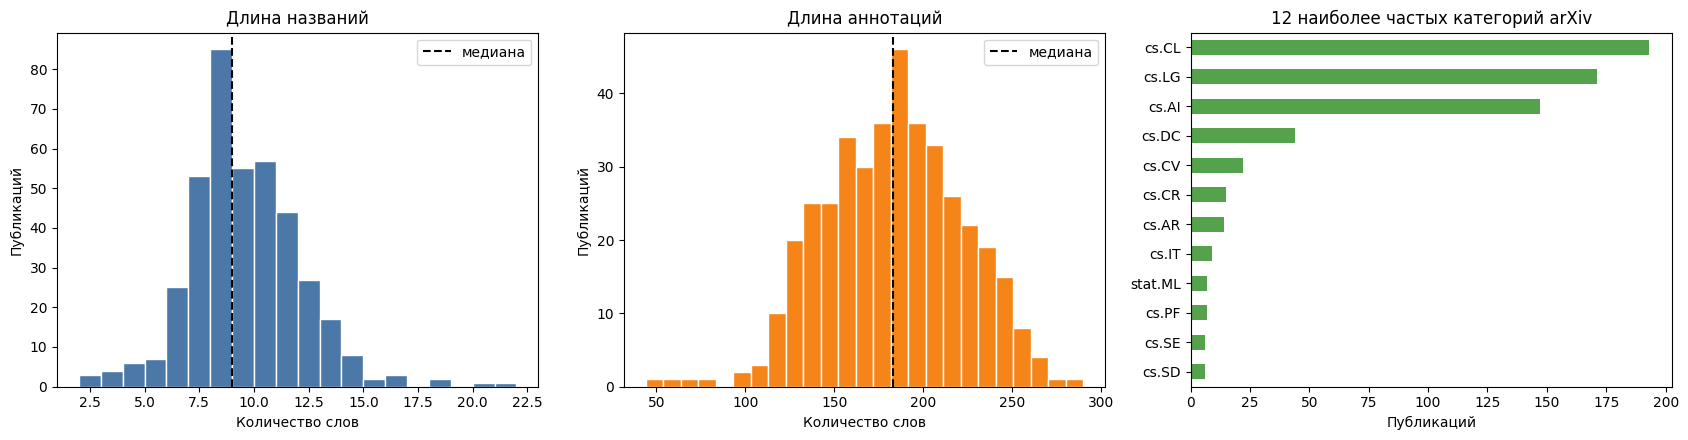

In [2]:
COUNT_RE = r"(?u)\b[A-Za-z][A-Za-z'-]+\b"

df["text"] = df["title"].fillna("") + " " + df["abstract"].fillna("")
df["title_word_count"] = df["title"].fillna("").str.findall(COUNT_RE).str.len()
df["abstract_word_count"] = df["abstract"].fillna("").str.findall(COUNT_RE).str.len()

all_authors = [a.strip() for x in df["authors"].fillna("") for a in x.split(";") if a.strip()]
all_categories = [c.strip() for x in df["categories"].fillna("") for c in x.split(";") if c.strip()]

normalized_titles = df["title"].fillna("").str.replace(r"\s+", " ", regex=True).str.strip().str.casefold()

quality_report = pd.Series({
    "Публикаций": len(df),
    "Период": f"{df.published.min().date()} - {df.published.max().date()}",
    "Уникальных авторов": len(set(all_authors)),
    "Медиана слов в названии": df.title_word_count.median(),
    "Медиана слов в аннотации": df.abstract_word_count.median(),
    "Дубликатов arXiv ID": int(df["arxiv_id"].duplicated().sum()),
    "Дубликатов названий": int(normalized_titles.duplicated().sum()),
    "Пустых названий": int(df["title"].fillna("").str.strip().eq("").sum()),
    "Пустых аннотаций": int(df["abstract"].fillna("").str.strip().eq("").sum()),
    "Пустых авторов": int(df["authors"].fillna("").str.strip().eq("").sum()),
    "Пустых категорий": int(df["categories"].fillna("").str.strip().eq("").sum()),
    "Некорректных дат": int(df[["published", "updated"]].isna().any(axis=1).sum()),
})
display(quality_report.to_frame("Значение"))
display(pd.Series(all_authors).value_counts().head(10).rename_axis("Автор").to_frame("Публикаций"))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].hist(df.title_word_count, bins=20, color="#4C78A8", edgecolor="white")
axes[0].axvline(df.title_word_count.median(), color="black", ls="--", label="медиана")
axes[0].set(title="Длина названий", xlabel="Количество слов", ylabel="Публикаций")
axes[0].legend()
axes[1].hist(df.abstract_word_count, bins=25, color="#F58518", edgecolor="white")
axes[1].axvline(df.abstract_word_count.median(), color="black", ls="--", label="медиана")
axes[1].set(title="Длина аннотаций", xlabel="Количество слов", ylabel="Публикаций")
axes[1].legend()
pd.Series(all_categories).value_counts().head(12).sort_values().plot.barh(ax=axes[2], color="#54A24B")
axes[2].set(title="12 наиболее частых категорий arXiv", xlabel="Публикаций", ylabel="")
plt.tight_layout()
plt.show()

Корпус содержит 400 публикаций. Выгрузка выполнялась в порядке убывания даты подачи, а пул публикаций по теме с 2020 года больше выбранного лимита, поэтому корпус охватывает период с 18 февраля по 16 октября 2026 года: это наиболее актуальные работы по теме, и требование "не старше 2020 года" выполнено для всех публикаций с запасом. Дубликатов идентификаторов и названий, пропусков в полях и некорректных дат нет, выгрузка чистая.

Оба распределения длин одномодальные: медианное название состоит из 9 слов, медианная аннотация из 183 слов, что типично для научных статей; у названий заметен правый хвост из-за составных названий с двоеточием.

В категориях преобладают cs.CL, cs.LG и cs.AI: speculative decoding является методом ускорения вывода LLM и находится на стыке обработки языка, машинного обучения и ИИ. Заметный вклад cs.DC и присутствие cs.CV, cs.AR, cs.CR отражают системную направленность метода и его распространение в смежные области (распределенный вывод, генерация видео, аппаратные реализации). Таблица самых продуктивных авторов показывает, что доминирующего коллектива нет: на лидера приходится 7 работ из 400, тему развивает множество независимых групп.

## Проверка закона Ципфа

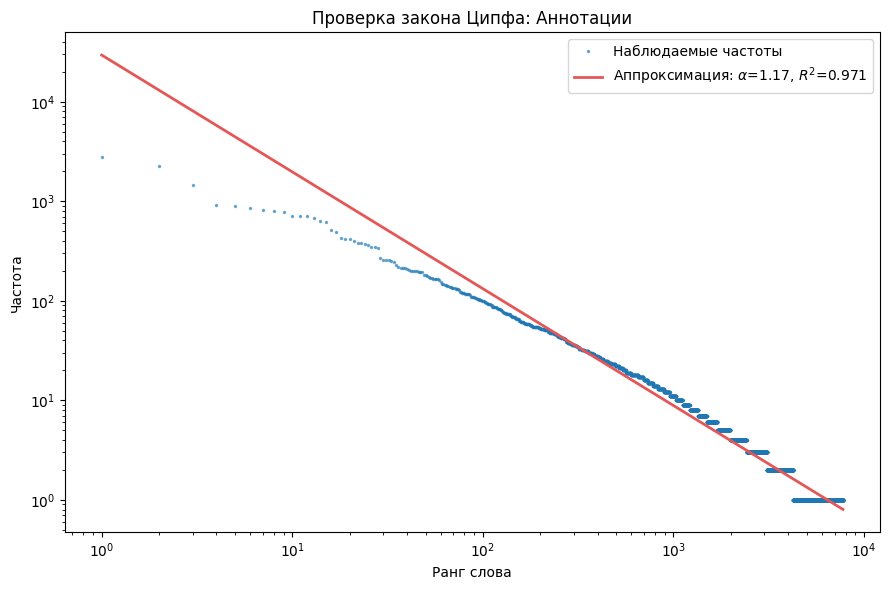

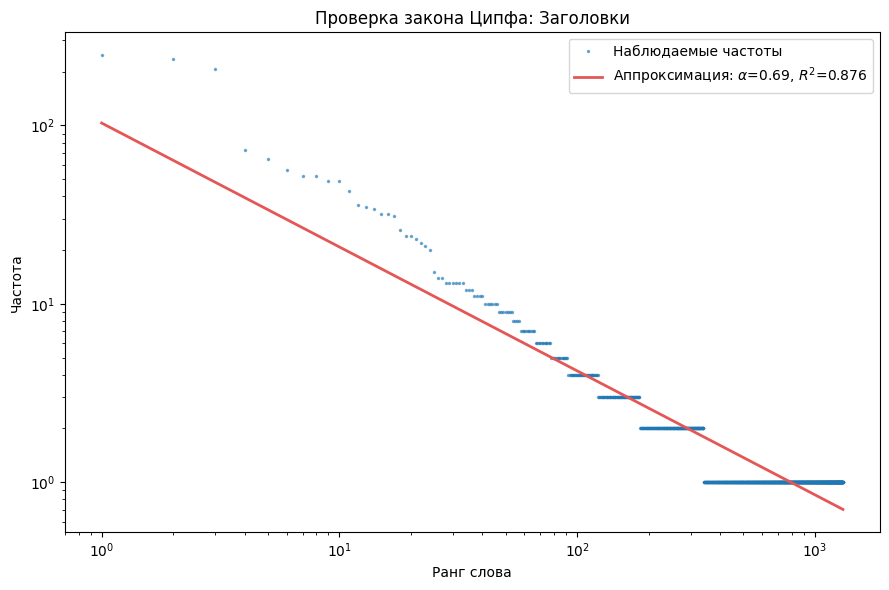

In [3]:
ZIPF_RE = r"(?u)\b[a-z][a-z'-]{1,}\b"

def zipf_check(texts, title):
    tokens = re.findall(ZIPF_RE, " ".join(texts).lower())
    freq = np.array(sorted(Counter(tokens).values(), reverse=True))
    ranks = np.arange(1, len(freq) + 1)
    log_ranks = np.log10(ranks)
    log_freq = np.log10(freq)
    slope, intercept = np.polyfit(log_ranks, log_freq, 1)
    alpha = -slope
    predicted = intercept + slope * log_ranks
    ss_res = np.sum((log_freq - predicted) ** 2)
    ss_tot = np.sum((log_freq - log_freq.mean()) ** 2)
    r_squared = 1 - ss_res / ss_tot
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.loglog(ranks, freq, ".", ms=3, alpha=0.55, label="Наблюдаемые частоты")
    ax.loglog(ranks, 10 ** predicted, color="#E45756", lw=2, label=fr"Аппроксимация: $\alpha$={alpha:.2f}, $R^2$={r_squared:.3f}")
    ax.set_xlabel("Ранг слова")
    ax.set_ylabel("Частота")
    ax.set_title(f"Проверка закона Ципфа: {title}")
    ax.legend()
    plt.tight_layout()
    plt.show()

zipf_check(df["abstract"].fillna(""), "Аннотации")
zipf_check(df["title"].fillna(""), "Заголовки")

В логарифмических координатах зависимость частоты слова от его ранга близка к линейной для обоих корпусов, что подтверждает выполнение закона Ципфа для собранного корпуса (точные значения показателя степени и коэффициента детерминации приведены в легендах графиков).

Для аннотаций показатель степени несколько превышает единицу, то есть частоты убывают немного быстрее классической формулировки закона с α=1: основную массу текста образуют термины, а не служебные слова. Отклонения от прямой заметны в голове распределения, где несколько самых частых служебных слов образуют плато ниже линии, и в разреженном хвосте гапаксов.

Для заголовков распределение заметно более пологое: заголовки короткие и состоят в основном из содержательных терминов, служебные слова в них почти не встречаются, поэтому голова распределения лежит выше аппроксимирующей прямой, а хвост распадается на дискретные ступеньки одинаковых частот. Из-за малого объема корпуса заголовков качество аппроксимации ниже, чем для аннотаций, однако монотонная степенная зависимость сохраняется.

Таким образом, корпус подчиняется стандартным статистическим закономерностям естественного языка, а частотная структура аннотаций и заголовков различается предсказуемым образом, поэтому корпус пригоден для дальнейшего частотного анализа и выделения ключевых слов.

## Ключевые слова публикаций

In [4]:
from nltk.stem.snowball import SnowballStemmer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer


stemmer = SnowballStemmer("english")
STOP_STEMS = {stemmer.stem(w) for w in ENGLISH_STOP_WORDS}
TOKEN_RE = r"(?u)\b[a-z][a-z-]{2,}\b"

def normalized_tokens(text):
    text = unicodedata.normalize("NFKC", str(text)).lower()
    text = text.replace("–", "-").replace("—", "-")
    tokens = re.findall(TOKEN_RE, text)
    return [stemmer.stem(t) for t in tokens if t not in ENGLISH_STOP_WORDS and stemmer.stem(t) not in STOP_STEMS]

vectorizer = TfidfVectorizer(
    tokenizer=normalized_tokens,
    token_pattern=None,
    lowercase=False,
    ngram_range=(1, 3),
    min_df=2,
    max_df=0.75,
    sublinear_tf=True,
    max_features=5000,
    norm="l2",
)
tfidf = vectorizer.fit_transform(df["text"])
terms = vectorizer.get_feature_names_out()

def row_top_terms(row_idx, k=10):
    row = tfidf.getrow(row_idx)
    order = np.argsort(row.data)[::-1][:k]
    return tuple(terms[row.indices[order]])

df["keywords"] = [row_top_terms(i) for i in range(len(df))]
keyword_counts = Counter(k for kws in df["keywords"] for k in set(kws))

display(df[["title", "keywords"]].head(10))
display(pd.DataFrame(keyword_counts.most_common(25), columns=["Ключевое слово", "Публикаций"]))

,title,keywords
0,Acceptance Is Not Speed: Length Inflation in T...,"(relax verif, relax, complet length, inflat, t..."
1,DLite: History-free Speculative Decoding for A...,"(histor context, histor, agent workload, agent..."
2,Trajectory-Triggered Sparse Collaborative Deco...,"(auc, weak, collabor, point, spars, evid, feat..."
3,BS-Spec: BFP-Based Bit-Sharing for Self-Specul...,"(mixed-precis, serv workload, tabl, precis, lo..."
4,On the SPOT: Enhancing Speculative Decoding fo...,"(dlms, order, transfer, diffus languag, diffus..."
5,LoopAhead: Speculating Ahead for Faster Decodi...,"(loop transform, recurr depth, loop, lookahead..."
6,HyCo: Hybrid Drafting for Cost-Efficient Mobil...,"(server, spec-bench, mtp, save, slm, npu, rela..."
7,Long-Context Drafting Does Not Require Long-Co...,"(million token, million, long-context, short, ..."
8,Speculative Sampling in Interactive Video Gene...,"(chunk, video, bidirect, video generat, sampl ..."
9,On-Policy Residual Learning for Diffusion Lang...,"(tpf, residu, dlms, on-polici, speed-qual, lea..."


,Ключевое слово,Публикаций
0,tree,24
1,diffus,20
2,agent,15
3,sampl,14
4,rollout,14
5,moe,13
6,expert,13
7,edg,13
8,self-specul,12
9,drafter,11


## Граф связей ключевых слов

Вершин: 149, ребер: 194
Компонент связности: 13, размеры: [85, 13, 13, 8, 8, 5, 5, 2, 2, 2, 2, 2, 2]
Доля вершин в крупнейшей компоненте: 57.0%


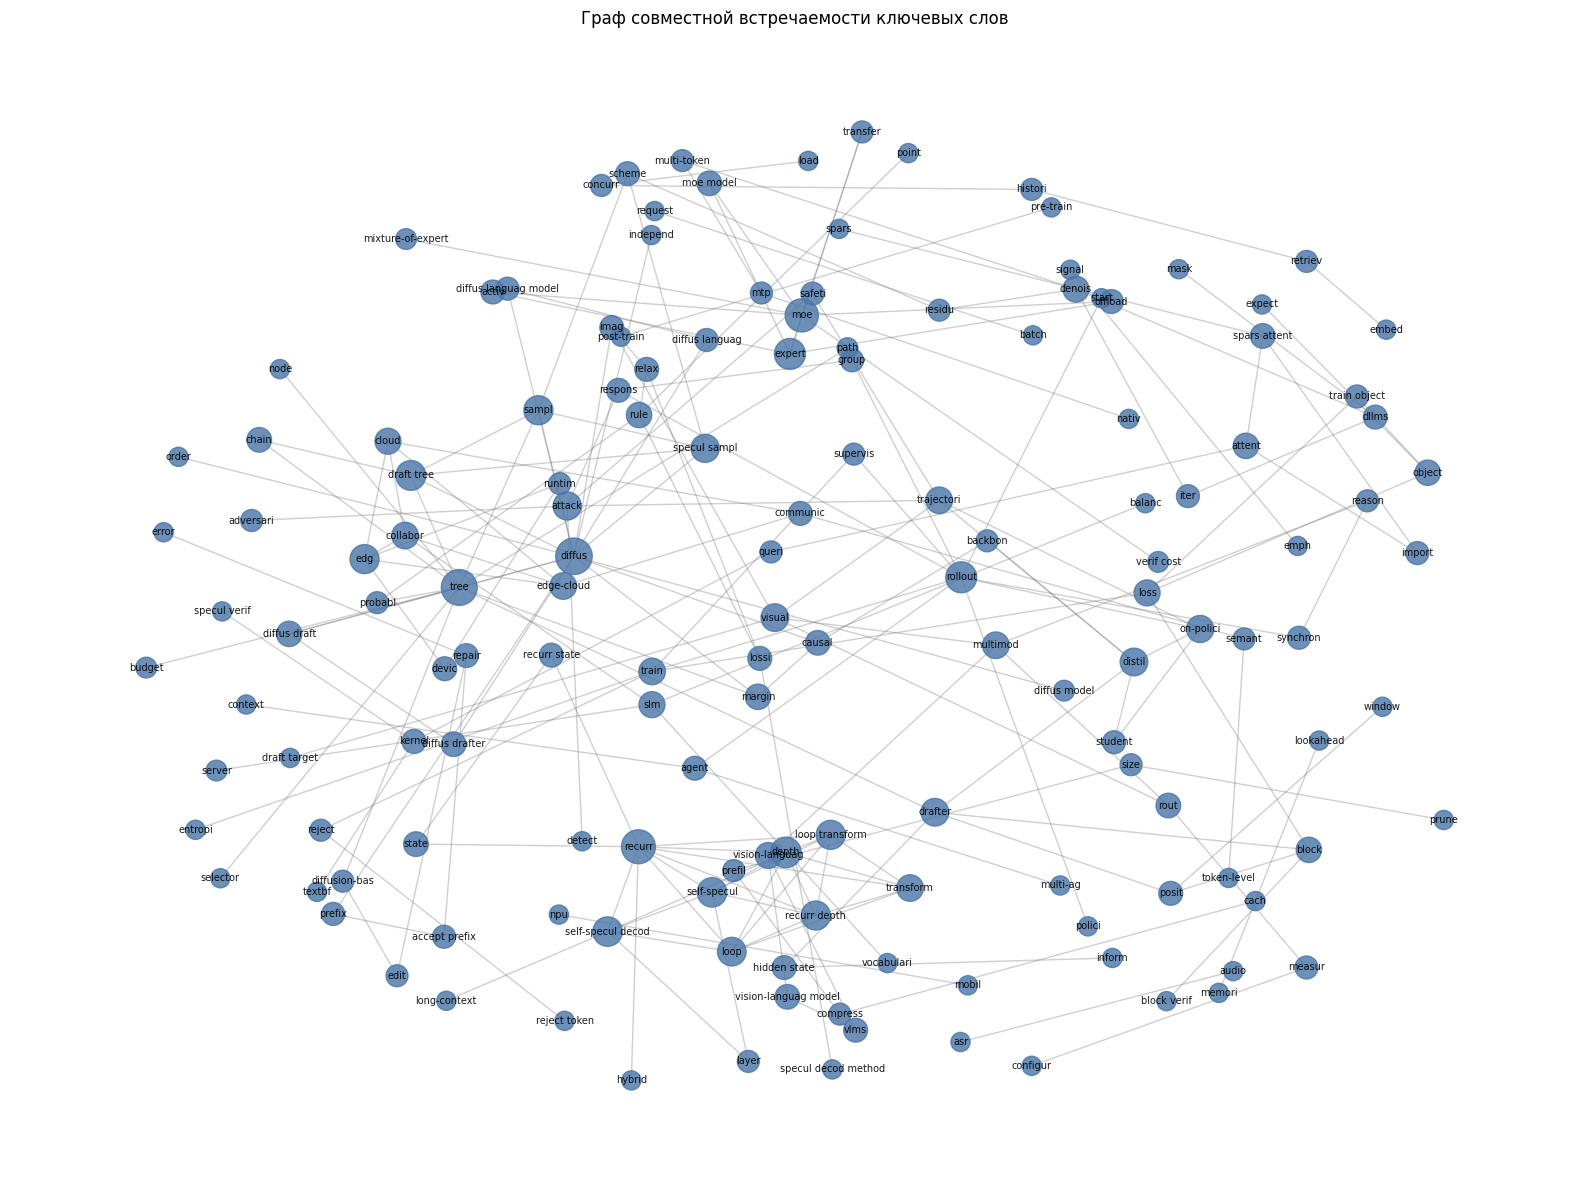

In [5]:
kept = [k for k, _ in keyword_counts.most_common(250)]
kept_set = set(kept)
edge_counter = Counter()
for kws in df["keywords"]:
    edge_counter.update(itertools.combinations(sorted(set(kws) & kept_set), 2))

Gk = nx.Graph()
for k in kept:
    Gk.add_node(k, document_frequency=keyword_counts[k])
for (u, v), w in edge_counter.items():
    if w >= 2:
        Gk.add_edge(u, v, weight=w, distance=1 / w)
Gk.remove_nodes_from(list(nx.isolates(Gk)))

components = sorted(nx.connected_components(Gk), key=len, reverse=True)
largest_component = Gk.subgraph(components[0]).copy()
weighted_degree = dict(Gk.degree(weight="weight"))

print(f"Вершин: {Gk.number_of_nodes()}, ребер: {Gk.number_of_edges()}")
print(f"Компонент связности: {len(components)}, размеры: {[len(c) for c in components]}")
print(f"Доля вершин в крупнейшей компоненте: {len(components[0]) / Gk.number_of_nodes():.1%}")

pos = nx.spring_layout(Gk, weight="weight", seed=42, k=0.65)
node_sizes = [50 + 100 * math.sqrt(weighted_degree[n]) for n in Gk]
labels = {n: n for n in Gk}

fig, ax = plt.subplots(figsize=(16, 12))
nx.draw_networkx_edges(Gk, pos, alpha=0.35, edge_color="#777777", ax=ax)
nx.draw_networkx_nodes(Gk, pos, node_size=node_sizes, node_color="#4C78A8", alpha=0.82, ax=ax)
nx.draw_networkx_labels(Gk, pos, labels=labels, font_size=7, alpha=0.9, ax=ax)
ax.set_title("Граф совместной встречаемости ключевых слов")
ax.axis("off")
plt.tight_layout()
plt.show()

## Кластеризация ключевых слов

Всего кластеров: 20, взвешенная модулярность Q = 0.836


,Кластер,Размер,Характерные термины
0,1,20,"diffus, tree, draft tree, sampl, specul sampl,..."
1,2,14,"rollout, train, agent, respons, synchron, grou..."
2,3,13,"recurr, depth, self-specul, self-specul decod,..."
3,4,13,"edg, collabor, edge-cloud, slm, cloud, devic, ..."
4,5,11,"drafter, loss, object, block, hidden state, po..."
5,6,10,"visual, multimod, vision-languag, rout, vision..."
6,7,9,"attack, distil, on-polici, trajectori, student..."
7,8,8,"attent, spars attent, kernel, import, queri, t..."
8,9,8,"denois, dllms, iter, mtp, residu, multi-token,..."
9,10,8,"moe, expert, moe model, offload, activ, transf..."


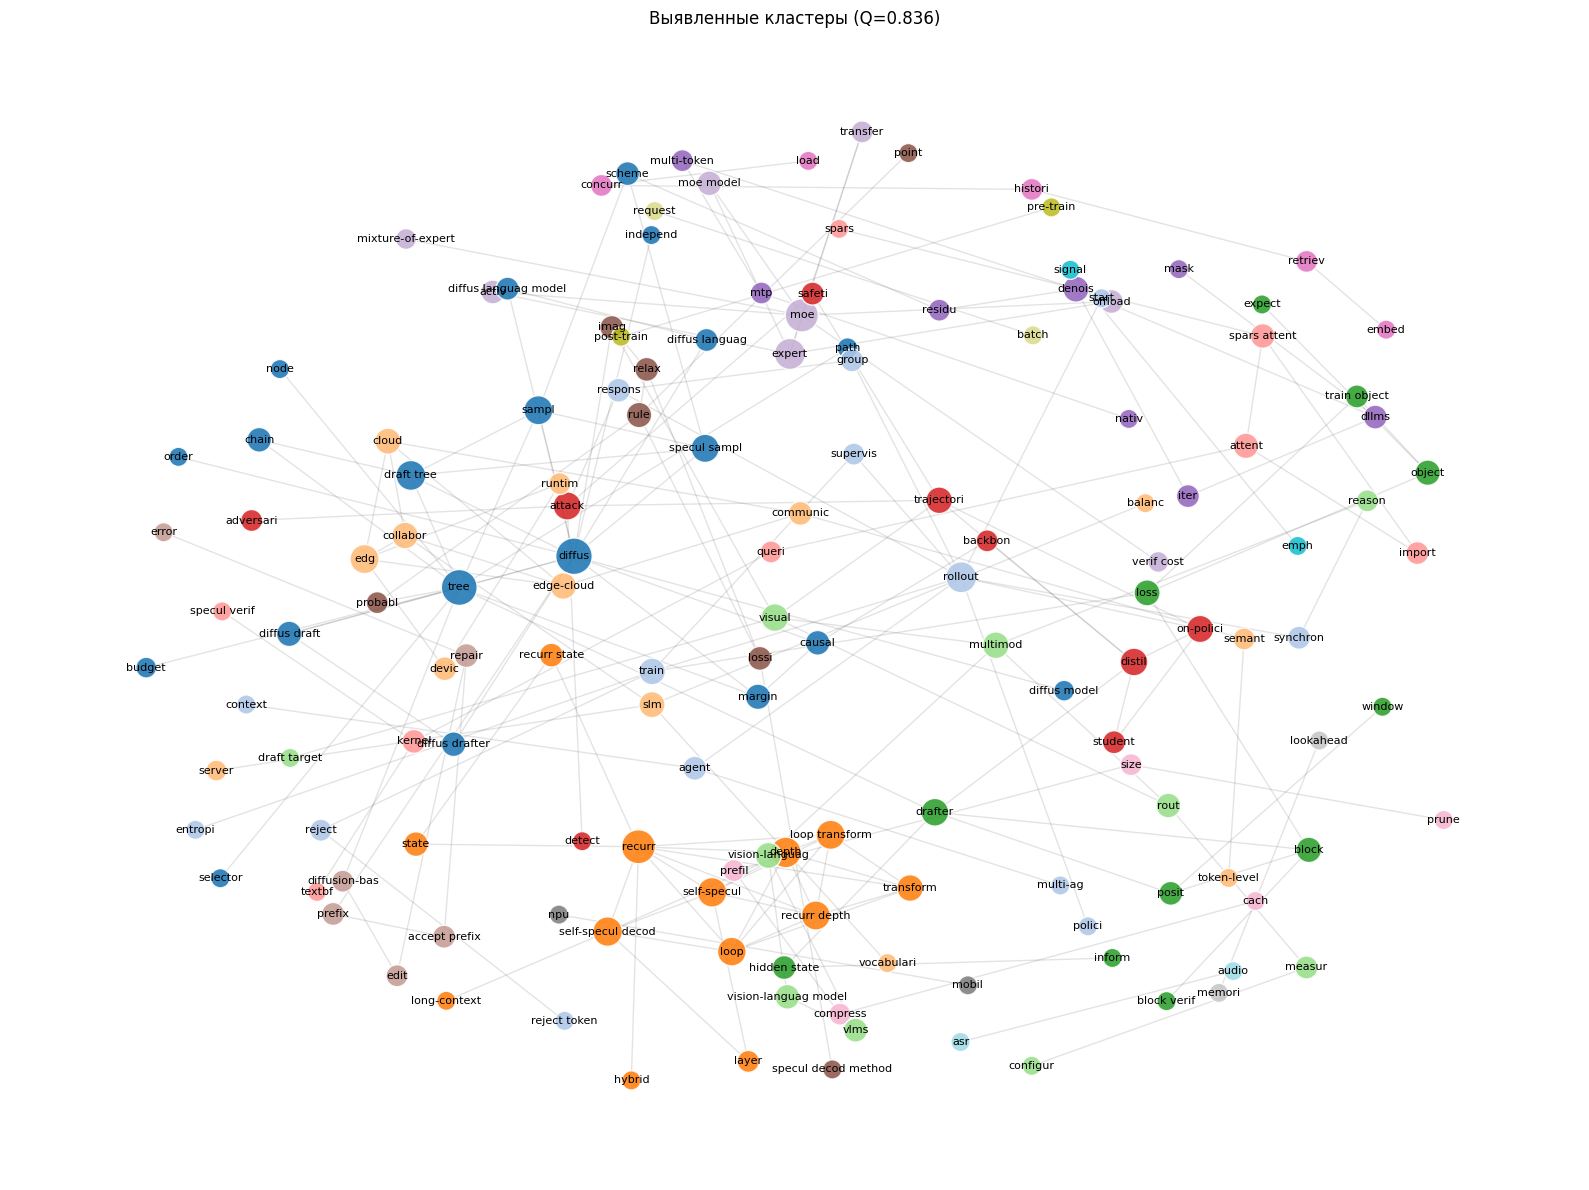

In [6]:
communities = list(nx.community.greedy_modularity_communities(Gk, weight="weight"))
modularity = nx.community.modularity(Gk, communities, weight="weight")
print(f"Всего кластеров: {len(communities)}, взвешенная модулярность Q = {modularity:.3f}")

community_of = {node: cid for cid, community in enumerate(communities, 1) for node in community}
nx.set_node_attributes(Gk, community_of, "community")

rows = []
for cid, community in enumerate(communities, 1):
    top_terms = sorted(community, key=lambda n: weighted_degree[n], reverse=True)[:12]
    rows.append({"Кластер": cid, "Размер": len(community), "Характерные термины": ", ".join(top_terms)})
cluster_table = pd.DataFrame(rows).sort_values("Размер", ascending=False).reset_index(drop=True)
display(cluster_table)

fig, ax = plt.subplots(figsize=(16, 12))
nx.draw_networkx_edges(Gk, pos, alpha=0.18, edge_color="#666666", ax=ax)
nx.draw_networkx_nodes(Gk, pos, node_size=node_sizes, node_color=[community_of[n] for n in Gk], cmap="tab20", alpha=0.88, edgecolors="white", ax=ax)
nx.draw_networkx_labels(Gk, pos, labels=labels, font_size=8, ax=ax)
ax.set_title(f"Выявленные кластеры (Q={modularity:.3f})")
ax.axis("off")
plt.tight_layout()
plt.show()

Алгоритм жадной оптимизации модулярности разбил 149 терминов графа совместной встречаемости на 20 сообществ, взвешенная модулярность Q=0.836 близка к единице, следовательно структура сообществ выражена четко: термины внутри кластера встречаются в одних публикациях заметно чаще, чем между кластерами.

Состав кластеров в таблице выше отражает реальную структуру направления. Крупнейшее сообщество объединяет термины диффузионного и древесного speculative sampling: diffus, tree, draft tree, sampl, то есть построение и верификацию черновых деревьев. Второе сообщество (rollout, train, respons, agent, synchron) соответствует работам, где speculative decoding ускоряет обучение агентов и RL-систем с параллельными rollout. Третье (recurr, depth, self-specul, self-specul decod) описывает self-speculative decoding и рекуррентные черновики на основе looped transformers. Четвертое (edg, edge-cloud, cloud, slm, collabor) покрывает edge- и cloud-edge вывод малых моделей. Далее следуют сообщества обучения и архитектуры драфтеров (drafter, loss, hidden st), мультимодальных и vision-language моделей (visual, multimod, vision-languag), on-policy дистилляции и безопасности (distil, on-polici, attack, trajectori), разреженного внимания и ядер (attent, spars attent, kernel), диффузионных языковых моделей и multi-token prediction (denois, dllms, mtp, residu), MoE-архитектур (moe, expert, offload), правил принятия и lossy-верификации (rule, relax, probabl, lossi), ремонта префиксов (repair, accept prefix, edit).

Малые кластеры размером 2-5 (mobil и npu, lookahead и memori, pre-train и post-train, request и batch, asr и audio, size, compress, cach) представляют узкие устойчивые сочетания: соответствующие работы упоминают ограниченный набор терминов вместе, поэтому такие группы образуют отдельные компоненты связности или периферию графа. Это согласуется с выводом выше: 13 компонент связности и 57% вершин в крупнейшей означают, что периферийные поднаправления темы слабо пересекаются с ядром по составу ключевых слов.

Таким образом, кластеры являются не случайными наборами слов, а содержательными поднаправлениями speculative decoding: от верификации черновых деревьев и диффузионных моделей до системных оптимизаций edge-вывода и MoE.

## Центральности ключевых слов

Топ 10 узлов по метрике: DEGREE


,degree,weighted_degree,cluster
diffus,0.178571,41,1
tree,0.154762,38,1
rollout,0.107143,20,2
sampl,0.059524,15,1
drafter,0.059524,12,5
draft tree,0.059524,17,1
trajectori,0.059524,10,7
attack,0.059524,13,7
visual,0.059524,12,6
distil,0.059524,12,7


Топ 10 узлов по метрике: BETWEENNESS


,betweenness,weighted_degree,cluster
tree,0.396897,38,1
diffus,0.338903,41,1
drafter,0.328194,12,5
rollout,0.228653,20,2
visual,0.220860,12,6
imag,0.203361,6,11
distil,0.199106,12,7
scheme,0.174412,6,1
on-polici,0.158945,11,7
residu,0.154618,4,9


Топ 10 узлов по метрике: CLOSENESS


,closeness,weighted_degree,cluster
tree,0.640953,38,1
diffus,0.626331,41,1
draft tree,0.624502,17,1
drafter,0.618861,12,5
distil,0.582582,12,7
imag,0.574658,6,11
margin,0.571262,8,1
diffus draft,0.570099,8,1
sampl,0.569878,15,1
chain,0.568895,7,1


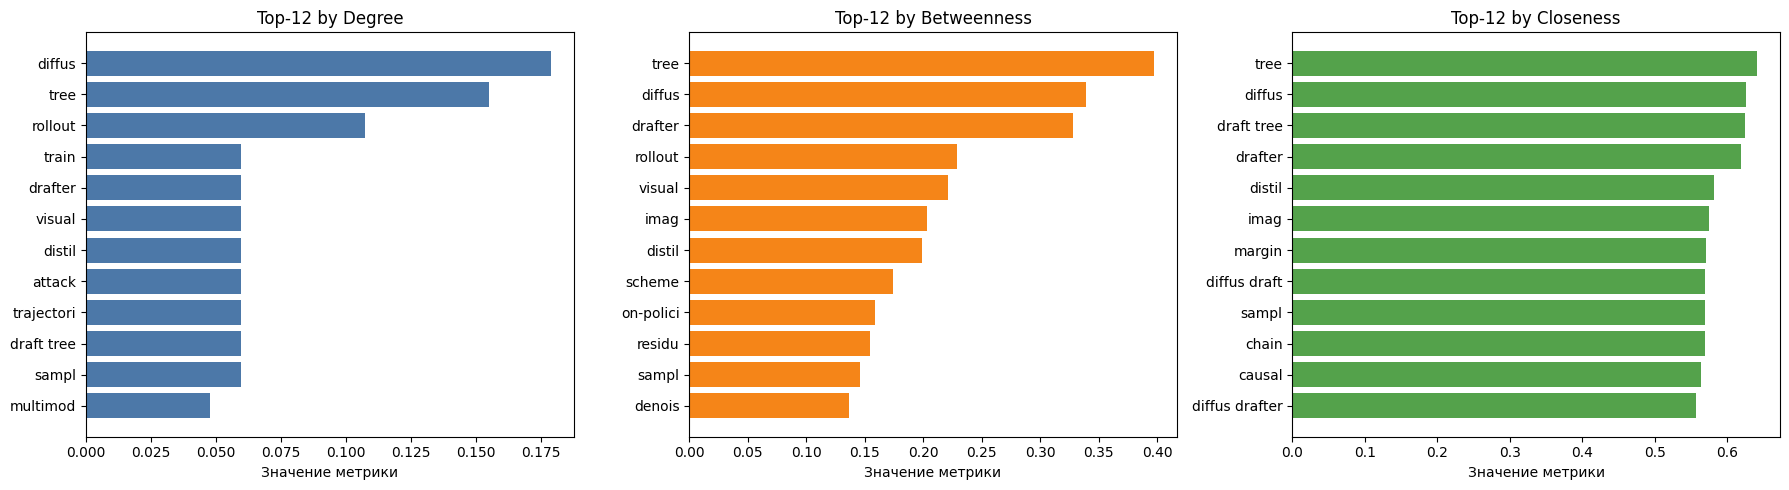

In [7]:
degree_c = nx.degree_centrality(largest_component)
betweenness_c = nx.betweenness_centrality(largest_component, weight="distance", normalized=True)
closeness_c = nx.closeness_centrality(largest_component, distance="distance")

centrality = pd.DataFrame({
    "degree": pd.Series(degree_c),
    "betweenness": pd.Series(betweenness_c),
    "closeness": pd.Series(closeness_c),
    "weighted_degree": pd.Series(dict(largest_component.degree(weight="weight"))),
    "cluster": pd.Series({n: community_of[n] for n in largest_component}).astype(int),
})

metrics = ["degree", "betweenness", "closeness"]
for metric in metrics:
    print(f"Топ 10 узлов по метрике: {metric.upper()}")
    display(centrality.nlargest(10, metric)[[metric, "weighted_degree", "cluster"]])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors = ["#4C78A8", "#F58518", "#54A24B"]
for ax, metric, color in zip(axes, metrics, colors):
    data = centrality.nlargest(12, metric).sort_values(metric)
    ax.barh(data.index, data[metric], color=color)
    ax.set_title(f"Top-12 by {metric.replace('_', ' ').title()}", fontsize=12)
    ax.set_xlabel("Значение метрики")
plt.tight_layout()
plt.show()

Все метрики рассчитаны на крупнейшей компоненте связности графа, чтобы значения между разными компонентами не сравнивались напрямую.

Degree centrality показывает, со сколькими другими терминами связан узел. Лидируют diffus, tree, rollout, drafter и draft tree: это понятия, входящие в наибольшее число пар совместной встречаемости, то есть понятийное ядро направления (древовидные черновики и их верификация, диффузионное speculative sampling, параллельные rollout). Высокий взвешенный степень тех же узлов подтверждает, что связи подкреплены многократными совместными появлениями в публикациях.

Betweenness centrality показывает, как часто термин лежит на кратчайших путях между другими узлами. Наряду с лидерами (tree, diffus) она поднимает drafter, visual, imag, distil, on-polici и residu: это термины-мосты, через которые проходят пути между сообществом древесной верификации, мультимодальным сообществом и сообществами дистилляции и обучения драфтеров; столбец cluster в таблицах выше показывает, что такие узлы принадлежат иным сообществам, чем часть их окружения. Высокий betweenness узла drafter при умеренном degree - типичный признак моста между поднаправлениями.

Closeness centrality показывает, насколько близко термин расположен ко всем остальным узлам. Лидеры tree, diffus, draft tree, drafter и distil достигают остальных терминов компоненты за минимальное число переходов, то есть именно эти понятия интегрируют граф темы.

Совпадение лидеров degree и closeness указывает на связное ядро темы, а расхождения в рейтинге betweenness выявляют структурно важные мосты между направлениями, которые не являются самыми частыми терминами корпуса.

## Граф публикаций

Вершин (статей): 400
Ребер (связей): 4316
Плотность графа: 0.0541


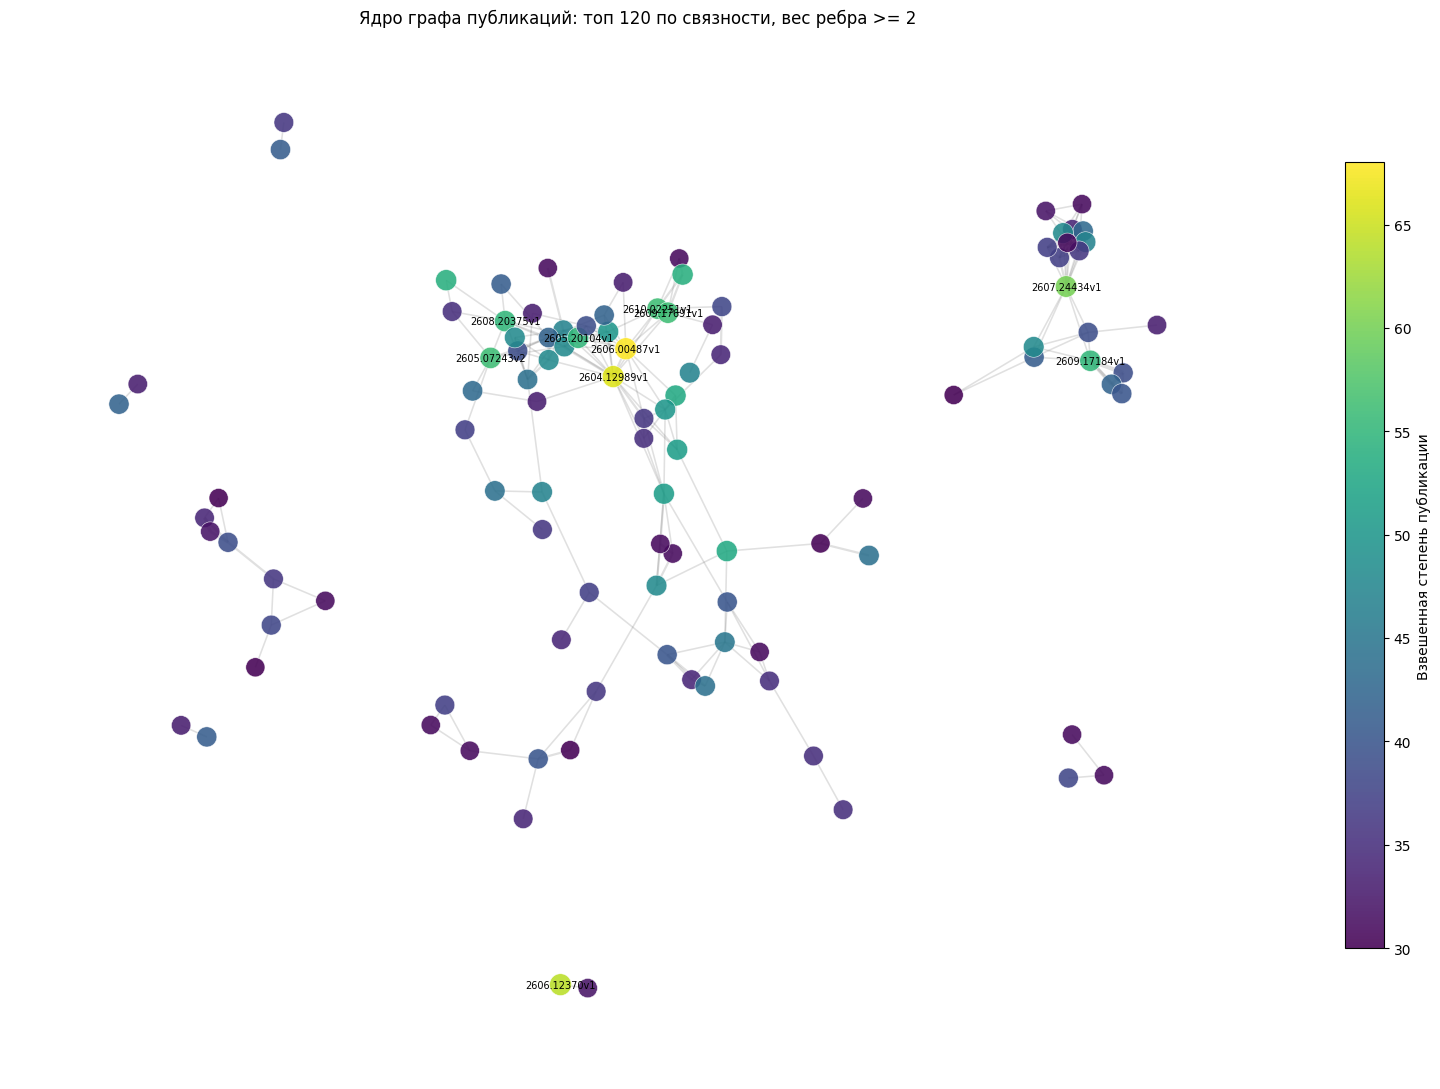

In [8]:
papers_by_keyword = defaultdict(list)
for i, kws in enumerate(df["keywords"]):
    for k in set(kws):
        papers_by_keyword[k].append(i)

paper_edges = Counter()
for ids in papers_by_keyword.values():
    if len(ids) > 1:
        paper_edges.update(itertools.combinations(sorted(ids), 2))

Gp = nx.Graph()
for i, row in df.iterrows():
    Gp.add_node(i, title=row.title, arxiv_id=row.arxiv_id, year=int(row.year))
for (u, v), w in paper_edges.items():
    Gp.add_edge(u, v, weight=w, distance=1 / w)

print(f"Вершин (статей): {Gp.number_of_nodes()}")
print(f"Ребер (связей): {Gp.number_of_edges()}")
print(f"Плотность графа: {nx.density(Gp):.4f}")

paper_weighted_degree = dict(Gp.degree(weight="weight"))
view_nodes = sorted(Gp, key=paper_weighted_degree.get, reverse=True)[:120]
Gp_view = nx.Graph(Gp.subgraph(view_nodes))
Gp_view.remove_edges_from([(u, v) for u, v, data in Gp_view.edges(data=True) if data["weight"] < 2])
Gp_view.remove_nodes_from(list(nx.isolates(Gp_view)))

pos_papers = nx.spring_layout(Gp_view, weight="weight", seed=42, k=0.32, iterations=100)
node_values = [paper_weighted_degree[n] for n in Gp_view]
node_sizes = [70 + 22 * math.sqrt(paper_weighted_degree[n]) for n in Gp_view]
edge_widths = [0.25 + 0.45 * Gp_view[u][v]["weight"] for u, v in Gp_view.edges()]

fig, ax = plt.subplots(figsize=(16, 11))
nx.draw_networkx_edges(Gp_view, pos_papers, width=edge_widths, alpha=0.20, edge_color="#666666", ax=ax)
nodes = nx.draw_networkx_nodes(Gp_view, pos_papers, node_size=node_sizes, node_color=node_values, cmap="viridis", alpha=0.88, linewidths=0.4, edgecolors="white", ax=ax)
label_nodes = sorted(Gp_view, key=paper_weighted_degree.get, reverse=True)[:10]
nx.draw_networkx_labels(Gp_view, pos_papers, labels={n: df.at[n, "arxiv_id"] for n in label_nodes}, font_size=7, ax=ax)
fig.colorbar(nodes, ax=ax, shrink=0.75, label="Взвешенная степень публикации")
ax.set_title("Ядро графа публикаций: топ 120 по связности, вес ребра >= 2")
ax.axis("off")
plt.tight_layout()
plt.show()

## Поиск публикаций
Функция search_publications выполняет свободный текстовый запрос. Запрос нормализуется и стеммизуется, по инвертированному индексу отбираются публикации-кандидаты, содержащие хотя бы один термин запроса, затем кандидаты ранжируются BM25. Пять лучших BM25-документов становятся стартовыми вершинами персонализированного PageRank на графе публикаций, поэтому итоговая оценка комбинирует текстовую релевантность и близость в графе: вес ребра между публикациями равен числу общих ключевых слов.

Функция recommend_similar возвращает публикации, наиболее близкие к заданной пользователем (по arXiv ID или фрагменту названия). Вся начальная вероятность помещается в заданную вершину, и PageRank распространяет ее по ребрам графа: чем больше общих ключевых слов и чем сильнее связи, тем выше ранг публикации. Дополнительно выводятся расстояние в графе и перечень общих ключевых слов.

In [9]:
from rank_bm25 import BM25Okapi

corpus_tokens = [normalized_tokens(text) for text in df["text"]]
bm25_model = BM25Okapi(corpus_tokens, k1=1.2, b=0.75)

term_to_docs = defaultdict(set)
for doc_id, tokens in enumerate(corpus_tokens):
    for token in set(tokens):
        term_to_docs[token].add(doc_id)

SEARCH_COLUMNS = ["score", "bm25", "graph_score", "matched_terms", "arxiv_id", "year", "title"]

def normalize_scores(values):
    values = np.asarray(values, dtype=float)
    if values.size == 0 or values.max() <= 0:
        return np.zeros_like(values)
    return values / values.max()

def search_publications(text_query, top_n=10, seed_count=5):
    query_terms = normalized_tokens(text_query)
    if not query_terms:
        return pd.DataFrame(columns=SEARCH_COLUMNS)
    candidate_sets = [term_to_docs[t] for t in set(query_terms) if t in term_to_docs]
    if not candidate_sets:
        return pd.DataFrame(columns=SEARCH_COLUMNS)
    candidate_ids = np.array(sorted(set.union(*candidate_sets)), dtype=int)
    bm25_scores = bm25_model.get_scores(query_terms)[candidate_ids]
    positive = bm25_scores > 0
    candidate_ids, bm25_scores = candidate_ids[positive], bm25_scores[positive]
    if len(candidate_ids) == 0:
        return pd.DataFrame(columns=SEARCH_COLUMNS)
    seed_order = np.argsort(-bm25_scores)[:seed_count]
    seed_ids, seed_scores = candidate_ids[seed_order], bm25_scores[seed_order]
    personalization = {int(d): float(s / seed_scores.sum()) for d, s in zip(seed_ids, seed_scores)}
    pagerank = nx.pagerank(Gp, alpha=0.85, personalization=personalization, weight="weight")
    graph_scores = np.array([pagerank[int(d)] for d in candidate_ids])
    bm25_norm = normalize_scores(bm25_scores)
    graph_norm = normalize_scores(graph_scores)
    final_scores = 0.6 * bm25_norm + 0.4 * graph_norm
    top_order = np.argsort(-final_scores)[:top_n]
    top_ids = candidate_ids[top_order]
    result = pd.DataFrame({
        "doc_id": top_ids,
        "score": final_scores[top_order],
        "bm25": bm25_scores[top_order],
        "graph_score": graph_norm[top_order],
        "matched_terms": [", ".join(t for t in dict.fromkeys(query_terms) if t in set(corpus_tokens[d])) for d in top_ids],
    }).set_index("doc_id").join(df[["arxiv_id", "year", "title"]])
    return result[SEARCH_COLUMNS]

def resolve_paper(query):
    query = str(query).strip().casefold()
    if not query:
        return None
    exact = df.index[df["arxiv_id"].str.casefold().eq(query)].tolist()
    if exact:
        return exact[0]
    fragment = df.index[df["title"].str.casefold().str.contains(re.escape(query), na=False)].tolist()
    return fragment[0] if fragment else None

def recommend_similar(query, top_n=10):
    source = resolve_paper(query)
    if source is None:
        return pd.DataFrame(columns=["pagerank", "graph_distance", "common_tags", "shared_keywords", "arxiv_id", "year", "title"])
    pagerank = nx.pagerank(Gp, alpha=0.85, personalization={source: 1.0}, weight="weight")
    pagerank.pop(source, None)
    top_ids = [d for d, _ in sorted(pagerank.items(), key=lambda item: item[1], reverse=True)[:top_n]]
    distances = nx.single_source_shortest_path_length(Gp, source)
    source_keywords = set(df.at[source, "keywords"])
    shared = [sorted(source_keywords & set(df.at[d, "keywords"])) for d in top_ids]
    result = df.loc[top_ids, ["arxiv_id", "year", "title"]].copy()
    result.insert(0, "shared_keywords", [", ".join(words[:5]) for words in shared])
    result.insert(0, "common_tags", [len(words) for words in shared])
    result.insert(0, "graph_distance", [distances.get(d, np.inf) for d in top_ids])
    result.insert(0, "pagerank", [pagerank[d] for d in top_ids])
    result.index.name = "doc_id"
    return result

In [10]:
print("Поиск наиболее близких публикаций для первой статьи корпуса")
display(recommend_similar(df.at[df.index[0], "arxiv_id"], top_n=5).round(4))

print("Свободный поиск по запросу о механике метода")
display(search_publications("draft model acceptance rate verification", top_n=5).round(4))

print("Свободный поиск по запросу о системном выводе")
display(search_publications("kv cache throughput serving", top_n=5).round(4))

Поиск наиболее близких публикаций для первой статьи корпуса


,pagerank,graph_distance,common_tags,shared_keywords,arxiv_id,year,title
doc_id,,,,,,,
6,0.0215,1,2,"relax, rule",2610.21436v1,2026,HyCo: Hybrid Drafting for Cost-Efficient Mobil...
175,0.0208,1,2,"lossi, relax",2607.26627v2,2026,Revisiting Lossy Verification in Speculative D...
205,0.0182,1,2,"lossi, rule",2609.02897v2,2026,"Margins, Not Windows: Training-Free Per-Step L..."
215,0.0128,1,1,relax,2606.27829v1,2026,CSD: Content-aware Speculative Decoding for Ef...
211,0.0123,1,1,relax,2606.30265v1,2026,When Is a Draft Accepted? A Theory of Acceptan...


Свободный поиск по запросу о механике метода


,score,bm25,graph_score,matched_terms,arxiv_id,year,title
doc_id,,,,,,,
391,0.9825,7.2466,0.9562,"draft, model, accept, rate",2602.23881v2,2026,LK Losses: Direct Acceptance Rate Optimization...
212,0.9723,6.9120,1.0000,"draft, model, rate",2606.30217v2,2026,"Before Thinking, Learn to Decide: Proactive Ro..."
280,0.9676,7.1143,0.9464,"draft, model, accept, rate, verif",2605.15051v1,2026,An Interpretable Latency Model for Speculative...
374,0.9538,7.0064,0.9343,"draft, model, accept, rate, verif",2603.12617v2,2026,When Drafts Evolve: Speculative Decoding Meets...
308,0.9237,6.7642,0.9091,"draft, model, accept, rate",2605.02888v2,2026,SpecKV: Adaptive Speculative Decoding with Com...


Свободный поиск по запросу о системном выводе


,score,bm25,graph_score,matched_terms,arxiv_id,year,title
doc_id,,,,,,,
274,0.9841,5.4931,0.9602,"cach, throughput, serv",2605.17613v1,2026,VeriCache: Turning Lossy KV Cache into Lossles...
156,0.9488,5.0244,1.0000,"cach, throughput, serv",2608.08097v1,2026,OasisKV: Scaling In-Decode KV Cache Beyond HBM...
26,0.9034,4.9054,0.9190,"cach, throughput, serv",2610.09025v2,2026,SPIN: Shadow Predictive Indexer for Sparse Att...
168,0.8718,4.8174,0.8640,"cach, serv",2608.01718v2,2026,LaCache: Robust Semantic Caching for LLM Serving
82,0.8452,4.7756,0.8090,"cach, throughput, serv",2609.24197v1,2026,H-Spec: Parallel Speculative Decoding Without ...


Тесты подтверждают работоспособность обоих режимов. В режиме похожих публикаций выдача состоит из работ, находящихся на расстоянии одного ребра от заданной и имеющих с ней общие ключевые слова (столбцы common_tags и shared_keywords), то есть граф корректно отражает тематическую близость статей.

В свободном поиске верхние строки занимают публикации, содержащие все термины запроса, при этом графовая составляющая оценки поднимает статьи, связанные ребрами большого веса с ядром темы, а не только точно совпадающие по тексту. Запросы разной тематики (механика черновика и верификации против системного вывода) возвращают разные смысловые группы работ, что согласуется с выделенными ранее кластерами ключевых слов.